# 4.3 · Token velocity the crypto way — turnover and NVT
### Module 4 · DeFi II · Topic 1 — a data lab

**The velocity problem.** In the framework of Domenicale, Avanzo & Schifanella (2026),
a token with no reason to be *held* is spent on receipt: the wealth-weighted holding time $\bar\tau\to 1$
and velocity $V$ rises, amplifying any supply imbalance.

But raw velocity is the wrong lens for crypto. Following the paper's **§5.2 reframing**, high velocity is
pathological only *relative to real exchange* — the condition is
$$V > V^{*} := \frac{PQ}{M},$$
i.e. velocity matters against absorptive capacity $Q$. In crypto this is captured by two market metrics:

- **turnover** $=\dfrac{\text{trading volume}}{\text{market cap}}$  (how many times the float changes hands per day — a velocity proxy);
- **NVT** $=\dfrac{\text{market cap}}{\text{transaction volume}}$  (the "P/E of crypto"; here $\text{NVT}_{\text{mkt}}=1/\text{turnover}$).

Grounded in **Campajola, D'Errico & Tessone (2022), *MicroVelocity*** and Fisher's $MV=PQ$.

**Data (free, no key):** CoinGecko (volume/market cap), Coin Metrics community API (on-chain activity).

## Setup

In [1]:
%matplotlib inline
import requests, json, os, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

CACHE = "data"; os.makedirs(CACHE, exist_ok=True)

def _cache(key):
    return os.path.join(CACHE, key + ".json")

def cget(url, params=None, key=None, pause=2.5):
    """GET JSON with a local cache, so the notebook re-runs offline without hitting rate limits."""
    if key and os.path.exists(_cache(key)):
        return json.load(open(_cache(key)))
    for _ in range(3):
        try:
            r = requests.get(url, params=params, timeout=40)
            if r.status_code == 200:
                data = r.json()
                if key:
                    json.dump(data, open(_cache(key), "w"))
                time.sleep(pause)
                return data
        except requests.RequestException:
            pass
        time.sleep(1.5)
    raise RuntimeError(f"failed: {url}")

# --- API endpoints (single source of truth) ---
CG = "https://api.coingecko.com/api/v3"          # market data: market cap, volume, price
CM = "https://community-api.coinmetrics.io/v4"    # on-chain activity (community tier)

TOKENS = {"ethereum": "ETH", "binancecoin": "BNB", "curve-dao-token": "CRV"}

## 1 · Turnover as a velocity proxy
turnover = 24h trading volume / market cap.

In [2]:
rows = []
for cid, sym in TOKENS.items():
    d = cget(f"{CG}/coins/{cid}", params={"localization":"false","tickers":"false",
             "market_data":"true","community_data":"false","developer_data":"false"}, key=f"coin_{cid}")
    m = d["market_data"]
    mc = m["market_cap"]["usd"]; vol = m["total_volume"]["usd"]
    rows.append(dict(token=sym, mcap_usd=round(mc), vol24h_usd=round(vol),
                     turnover=round(vol/mc,4), NVT_mkt=round(mc/vol,1)))
vel = pd.DataFrame(rows).sort_values("turnover"); vel

,token,mcap_usd,vol24h_usd,turnover,NVT_mkt
1,BNB,81321123402,514630342,0.0063,158.0
0,ETH,227329692699,6902821917,0.0304,32.9
2,CRV,395015087,59935574,0.1517,6.6


## 2 · Reading turnover and NVT
High turnover (low NVT) = the float trades fast relative to its value — a velocity-trap signal for a token meant to be held. Low turnover (high NVT) = the token is held.

In [3]:
for _, r in vel.iterrows():
    tag = "held (low velocity)" if r.turnover < 0.02 else ("moderate" if r.turnover < 0.08 else "HIGH velocity")
    print(f"  {r.token}: turnover={r.turnover:.4f}  NVT_mkt={r.NVT_mkt:.1f}   -> {tag}")

  BNB: turnover=0.0063  NVT_mkt=158.0   -> held (low velocity)
  ETH: turnover=0.0304  NVT_mkt=32.9   -> moderate
  CRV: turnover=0.1517  NVT_mkt=6.6   -> HIGH velocity


## 3 · On-chain activity (Coin Metrics community API)
The *proper* NVT uses on-chain transaction value; the community tier exposes market cap, supply, transaction count and active addresses (transfer-value is a paid metric — flagged as an extension).

In [4]:
cm = cget(f"{CM}/timeseries/asset-metrics",
          params={"assets": "eth", "metrics": "CapMrktCurUSD,SplyCur,TxCnt,AdrActCnt",
                  "frequency": "1d", "page_size": 1, "end_time": "2026-08-10"},
          key="cm_eth", pause=0)
d = cm["data"][0]
print("ETH on-chain snapshot (Coin Metrics community):")
print(f"  market cap       = ${float(d['CapMrktCurUSD']):,.0f}")
print(f"  supply           = {float(d['SplyCur']):,.0f} ETH")
print(f"  daily tx count   = {int(float(d['TxCnt'])):,}")
print(f"  active addresses = {int(float(d['AdrActCnt'])):,}")
print("\nNote: on-chain transfer-value NVT (TxTfrValAdjUSD) is a paid metric -> see 'Your task'.")

ETH on-chain snapshot (Coin Metrics community):
  market cap       = $228,179,613,240
  supply           = 121,943,191 ETH
  daily tx count   = 2,315,258
  active addresses = 866,768

Note: on-chain transfer-value NVT (TxTfrValAdjUSD) is a paid metric -> see 'Your task'.


## 4 · The V* condition and the structural fix
High velocity is only a *trap* when it outpaces exchange ($V>V^{*}=PQ/M$). The design fix is a reason to
**hold**: staking, governance, vote-escrow, time-locked rewards — all raise $\bar\tau$ and lower $V$.

- **BNB** (turnover ≈ 0.006): low velocity — utility + a deflationary auto-burn give a reason to hold.
- **ETH** (≈ 0.030): moderate; a large share of supply is *staked*, removing it from circulation.
- **CRV** (≈ 0.152, ~5× ETH): the highest turnover here — its mitigant is **veCRV locking** (up to 4 years),
  which converts fast-moving CRV into locked, vote-weighted balances.

## 5 · Comparison — velocity across tokens

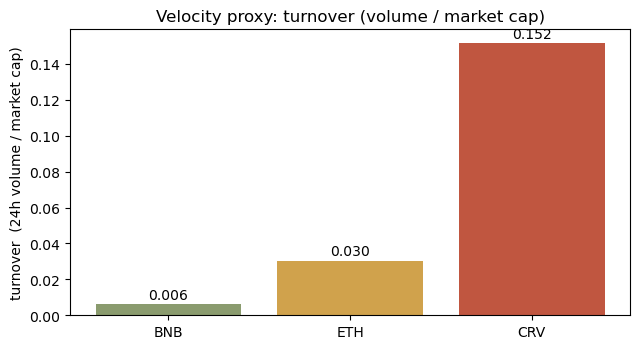

In [5]:
v = vel.sort_values("turnover")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
cols = ["#8a9b6e" if t < 0.02 else ("#d0a24c" if t < 0.08 else "#c05640") for t in v["turnover"]]
ax.bar(v["token"], v["turnover"], color=cols)
ax.set_ylabel("turnover  (24h volume / market cap)")
ax.set_title("Velocity proxy: turnover (volume / market cap)")
for i, t in enumerate(v["turnover"]):
    ax.text(i, t + 0.003, f"{t:.3f}", ha="center")
plt.tight_layout(); plt.show()

## 6 · Interpretation
- Turnover separates tokens that are **held** (BNB, ETH — utility, burn, staking) from those that **circulate fast
  relative to value** (CRV). High turnover is not automatically bad — by $V>V^{*}$ it is only a problem when it
  outpaces real transaction volume — but for a token whose thesis is *holding for governance/fees*, high turnover
  signals a missing holding incentive.
- CRV pairs the highest turnover with the highest emission (4.2): the supply-side signals reinforcing.

## Caveats
- CoinGecko volume includes CEX and can be inflated by wash trading; **turnover is a market proxy**, not on-chain
  velocity. On-chain NVT (Coin Metrics/Glassnode adjusted transfer value) is the more faithful measure.
- NVT has no absolute threshold — read it relatively and over time.
- A token can be supply-sound yet circulate too fast, and vice-versa; read the supply and velocity measures together.

## Your task
1. Compute turnover and NVT for two more tokens; place them on the velocity axis and name the holding incentive that would help each.
2. Retrieve the **staking / lock ratio** for one token (e.g. staked-ETH share from beaconcha.in, or locked veCRV from Curve) and relate it to that token's turnover.
3. Using notebook 4.2's supply figure, compute $V^{*}=PQ/M$ for one token from its transaction volume and state whether observed velocity exceeds it.